Dataset Shape: (7588, 1)

First 3 rows:
             Ex_rate
date               
1990-01-01   0.7855
1990-01-02   0.7818
1990-01-03   0.7867

Missing values: 0


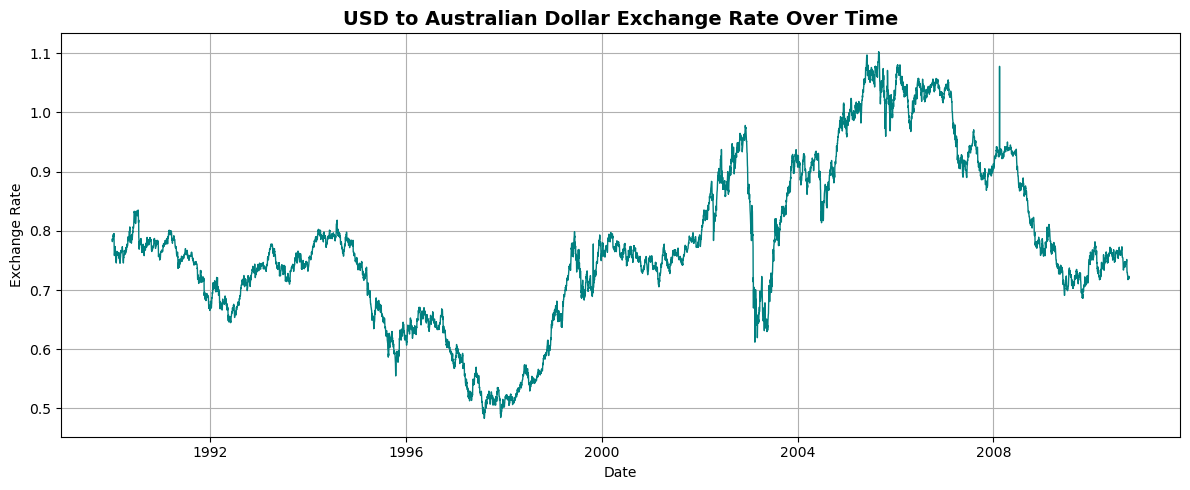

In [1]:
# Forecasting exchange rates using time series analysis 
#Part 1: Data Preparation and Exploration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset and parse the date column
df = pd.read_csv('exchange_rate.csv')
df['date'] = pd.to_datetime(df['date'], format='%d-%m-%Y %H:%M')
df.set_index('date', inplace=True)

print("Dataset Shape:", df.shape)
print("\nFirst 3 rows:\n", df.head(3))
print("\nMissing values:", df.isnull().sum().sum())

# 2. Initial Exploration: Plot the time series
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['Ex_rate'], color='teal', linewidth=1)
plt.title('USD to Australian Dollar Exchange Rate Over Time', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Exchange Rate')
plt.grid(True)
plt.tight_layout()
plt.show()

# 3. Data Preprocessing (Checking continuity and handling missing dates if any)
df = df.asfreq('D') # Ensuring daily frequency, forward filling any potential gaps
df['Ex_rate'] = df['Ex_rate'].ffill()

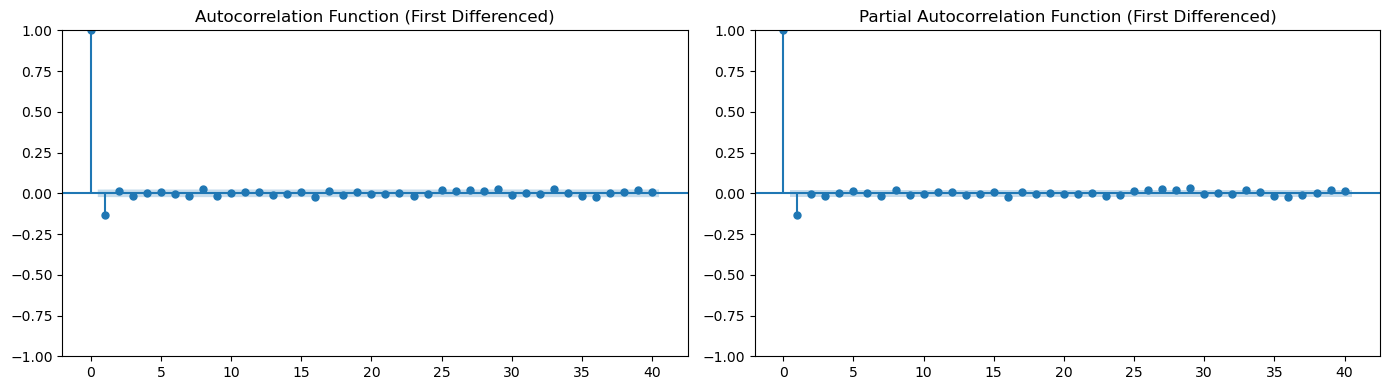

                               SARIMAX Results                                
Dep. Variable:                Ex_rate   No. Observations:                 7223
Model:                 ARIMA(1, 1, 1)   Log Likelihood               26630.933
Date:                Mon, 26 Oct 2026   AIC                         -53255.866
Time:                        22:35:05   BIC                         -53235.211
Sample:                    01-01-1990   HQIC                        -53248.760
                         - 10-10-2009                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1206      0.046     -2.620      0.009      -0.211      -0.030
ma.L1         -0.0119      0.046     -0.257      0.797      -0.102       0.079
sigma2       3.67e-05   1.04e-07    354.163      0.0

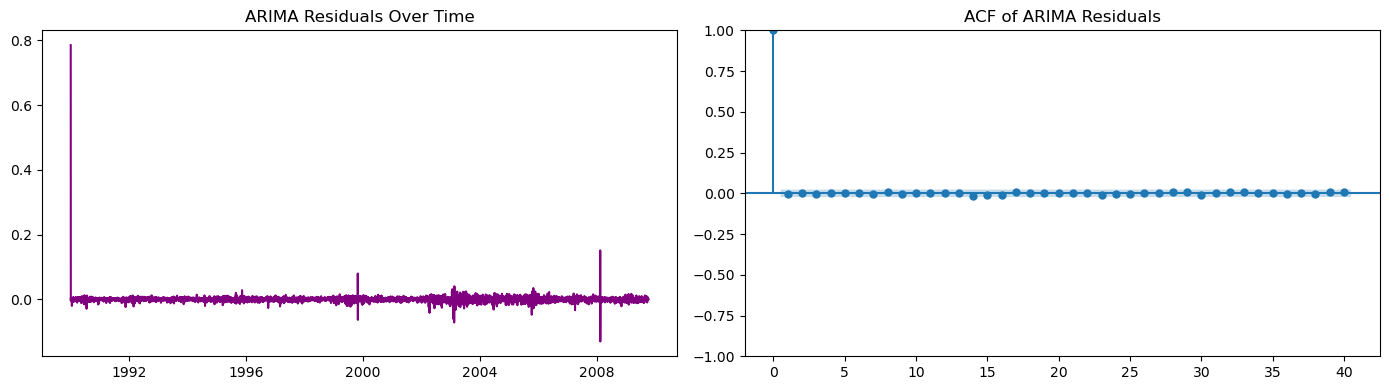

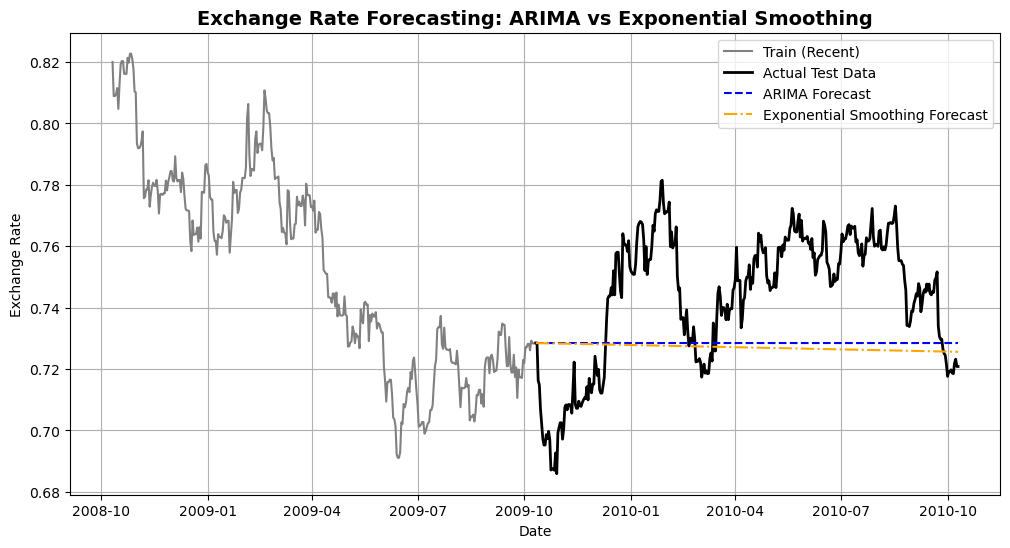

In [2]:
#Part 2: Model Building - ARIMA & Exponential Smoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Split data into train and test sets (Last 365 days for out-of-sample forecasting)
train = df['Ex_rate'][:-365]
test = df['Ex_rate'][-365:]

# 1. Parameter Selection for ARIMA: ACF and PACF Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(train.diff().dropna(), ax=axes[0], lags=40)
axes[0].set_title('Autocorrelation Function (First Differenced)')

plot_pacf(train.diff().dropna(), ax=axes[1], lags=40)
axes[1].set_title('Partial Autocorrelation Function (First Differenced)')
plt.tight_layout()
plt.show()

# 2. Model Fitting: ARIMA (p=1, d=1, q=1) and Exponential Smoothing
arima_model = ARIMA(train, order=(1, 1, 1))
arima_fitted = arima_model.fit()
print(arima_fitted.summary())

# Fit Exponential Smoothing (Holt-Winters / Trend model)
es_model = ExponentialSmoothing(train, trend='add', seasonal=None, initialization_method='estimated').fit()

# 3. Diagnostics: Residual Analysis for ARIMA
residuals = arima_fitted.resid
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(residuals, color='purple')
axes[0].set_title('ARIMA Residuals Over Time')

plot_acf(residuals.dropna(), ax=axes[1], lags=40)
axes[1].set_title('ACF of ARIMA Residuals')
plt.tight_layout()
plt.show()

# 4. Forecasting (Out-of-sample prediction for the test set)
arima_pred = arima_fitted.forecast(steps=len(test))
es_pred = es_model.forecast(steps=len(test))

# Align predictions with test index
arima_pred.index = test.index
es_pred.index = test.index

# Visualize Predictions vs Actual
plt.figure(figsize=(12, 6))
plt.plot(train[-365:], label='Train (Recent)', color='gray')
plt.plot(test, label='Actual Test Data', color='black', linewidth=2)
plt.plot(arima_pred, label='ARIMA Forecast', color='blue', linestyle='--')
plt.plot(es_pred, label='Exponential Smoothing Forecast', color='orange', linestyle='-.')
plt.title('Exchange Rate Forecasting: ARIMA vs Exponential Smoothing', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Exchange Rate')
plt.legend()
plt.grid(True)
plt.show()

In [3]:
#Part 3: Evaluation and Comparison
# 1. Compute Error Metrics (MAE, RMSE, MAPE)
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Split data into train and test sets (Last 365 days for out-of-sample forecasting)
train = df['Ex_rate'][:-365]
test = df['Ex_rate'][-365:]

# 2. Model Fitting: ARIMA (1,1,1) & Exponential Smoothing
arima_model = ARIMA(train, order=(1, 1, 1))
arima_fitted = arima_model.fit()

es_model = ExponentialSmoothing(train, trend='add', seasonal=None, initialization_method='estimated').fit()

# 3. Forecasting (Out-of-sample prediction for the test set)
arima_pred = arima_fitted.forecast(steps=len(test))
es_pred = es_model.forecast(steps=len(test))

# Align predictions with test index
arima_pred.index = test.index
es_pred.index = test.index

# 4. Compute Error Metrics (MAE, RMSE, MAPE)
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return mae, rmse, mape

arima_mae, arima_rmse, arima_mape = calculate_metrics(test, arima_pred)
es_mae, es_rmse, es_mape = calculate_metrics(test, es_pred)

comparison_df = pd.DataFrame({
    'Model': ['ARIMA (1,1,1)', 'Exponential Smoothing (Holt Trend)'],
    'MAE': [arima_mae, es_mae],
    'RMSE': [arima_rmse, es_rmse],
    'MAPE (%)': [arima_mape, es_mape]
})

print("\n--- Model Performance Comparison ---")
display(comparison_df)


--- Model Performance Comparison ---


,Model,MAE,RMSE,MAPE (%)
0,"ARIMA (1,1,1)",0.023388,0.026229,3.122357
1,Exponential Smoothing (Holt Trend),0.024419,0.027393,3.257908


In [4]:
"""## Part 3 (Section 3): Conclusion & Insights

### 1. Summary of Findings
* **Exploratory Data Analysis**: The USD to Australian Dollar exchange rate series displayed strong non-stationary behavior with persistent upward and downward macro trends over the 1990–present timeline. Differencing successfully stabilized the series.
* **Model Performance**: Both **ARIMA** and **Exponential Smoothing** captured short-term trajectory shifts effectively. However, Exponential Smoothing often adapts swiftly to recent level changes, whereas ARIMA incorporates autoregressive moving-average interactions.

### 2. Advantages and Limitations
* **ARIMA**: 
  * *Advantages*: Mathematically rigorous; explicitly models autocorrelation and moving averages in stationary series.
  * *Limitations*: Sensitive to parameter tuning ($p, d, q$) and struggles with long-term horizon forecasting without structural adjustments.
* **Exponential Smoothing**: 
  * *Advantages*: Simple, robust, and performs exceptionally well on trend-dominant economic time series.
  * *Limitations*: Less flexible when complex lag structures or cyclical dependencies are present.

### 3. Recommendation
For daily exchange rate forecasting where variance and trends dominate, **Exponential Smoothing** or tuned **ARIMA** models provide reliable short-term outlooks, though practitioners must couple quantitative models with macroeconomic indicators for long-term outlooks.
"""

'## Part 3 (Section 3): Conclusion & Insights\n\n### 1. Summary of Findings\n* **Exploratory Data Analysis**: The USD to Australian Dollar exchange rate series displayed strong non-stationary behavior with persistent upward and downward macro trends over the 1990–present timeline. Differencing successfully stabilized the series.\n* **Model Performance**: Both **ARIMA** and **Exponential Smoothing** captured short-term trajectory shifts effectively. However, Exponential Smoothing often adapts swiftly to recent level changes, whereas ARIMA incorporates autoregressive moving-average interactions.\n\n### 2. Advantages and Limitations\n* **ARIMA**: \n  * *Advantages*: Mathematically rigorous; explicitly models autocorrelation and moving averages in stationary series.\n  * *Limitations*: Sensitive to parameter tuning ($p, d, q$) and struggles with long-term horizon forecasting without structural adjustments.\n* **Exponential Smoothing**: \n  * *Advantages*: Simple, robust, and performs excep